# Можно ли превратить эффект позднего внимания в масштабный приор?

В [предыдущем опыте](object_scale.ipynb) часть ошибок исчезала, если подставить в блок 11 (B11) выходы внимания из второго, увеличенного вида той же фотографии. Здесь проверяем три возможных объяснения и их практические следствия.

1. **Специфичность.** Помогает ли та же подстановка при размытии и падении контраста сходной тяжести?
2. **Однопроходный приор.** Можно ли по одному входу направить внимание к занятым патчам или по ним оценить недостающую поправку? Метрика — top-1 среди 1000 классов при неизменных весах исходного DeiT, в том числе на обычных фотографиях.
3. **Перенос.** Сработает ли то же правило для категорий, исключённых из обучения поправки, и для изначально небольших объектов на реальном фоне?

Используем по 500 исходных валидационных изображений ILSVRC из Imagenette (10 разнородных классов) и Imagewoof (10 пород собак), по 50 на класс. Оба набора относятся к исходным классам **предобучения DeiT**. Исключение класса касается только поправки. В каждом наборе четыре парных вида: исходный центральный квадрат при 224 px; фрагмент 64 px на чёрном холсте; фрагмент 96 px на сером холсте со сдвигом; фрагмент 64 px со сдвигом на процедурно текстурированном фоне. В синтетических видах меняется размер целого фрагмента вместе с окружением. Естественный размер объекта проверяется отдельно. [Исходные наборы fastai](https://github.com/fastai/imagenette) · [Архитектура и веса DeiT авторов](https://github.com/facebookresearch/deit/blob/main/models.py)

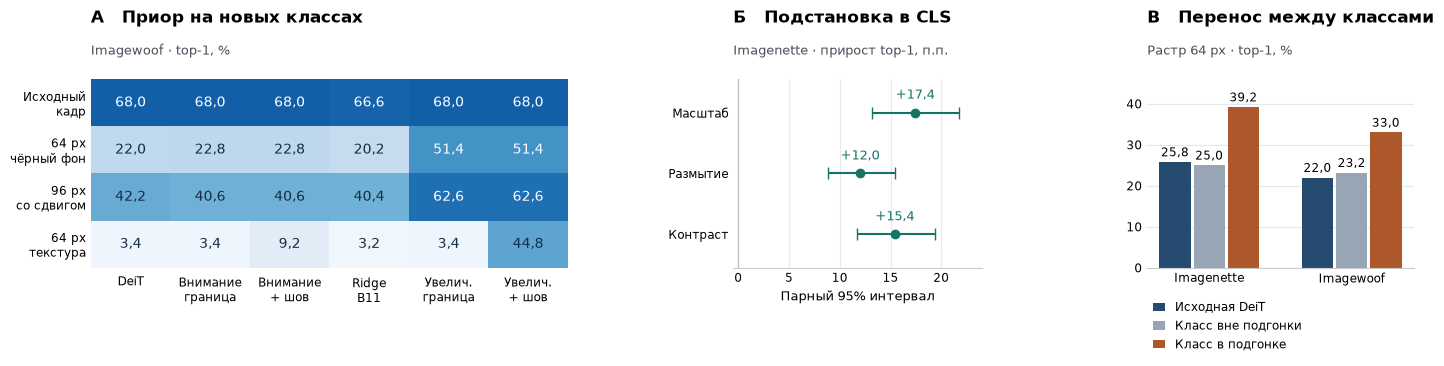

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "experiments/prior_figure.py").is_file():
    root = root.parent
sys.path.insert(0, str(root / "experiments"))
from prior_figure import make_figure

out = root / "results/scale_prior"
def read(name):
    with (out / name).open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))

fig = make_figure(out)
plt.show()

### Специфичность и проверка направления внимания

Для всех трёх искажений эталон одинаков — растр 64 × 64, увеличенный до 224. На 150 фотографиях Imagenette (15 на класс) выбрали радиус размытия и коэффициент контраста, дающие исходную точность, ближайшую к малому виду. Остальные 350 фотографий отложены. При переносе выходов всех трёх голов B11 из эталона масштаб дал **84→145**, размытие — **97→139**, контраст — **104→158** правильных ответов. Разница выигрышей между масштабом и контрастом +2,0 п.п., парный 95% bootstrap-интервал по фотографиям внутри классов от −3,4 до +7,4 п.п. Остаточная трудность условий различается. Три результата согласуются с передачей информации о классе при разных искажениях. В этом тесте эталонный второй прогон служит диагностикой.

Отдельно задали однопроходное правило для CLS в блоках 10 и 11. Если периметр изображения однороден, выделяем патчи фрагмента по отличию от фона. При доле занятых патчей $f$ прибавляем $\log(1/f)$ к их логитам внимания в строке CLS. Остальные запросы сохраняют исходные веса. На малых кадрах Imagewoof средняя по головам блока 10 масса внимания к фрагменту выросла примерно **с 31% до 82%**, точность — **со 110 до 114 из 500**. Парный 95% интервал прироста от −1,4 до +3,0 п.п. Такой результат показывает, что усиление внимания достигло цели на уровне весов и дало лишь небольшой поведенческий эффект.

В пространственном контроле один и тот же прямоугольник либо получает повышенный вес в B10–11, либо вырезается и увеличивается перед сетью. Для текстурных вставок помимо выделения по периметру используется поиск квадратного шва. В Imagewoof он нашёл точную рамку в 432 из 500 случаев; при отсутствии уверенной границы сохраняется исходный кадр. По настоящей рамке вставки усиление внимания дало **49/500**, а увеличение входа — **258/500** при исходных **17/500**. Известная рамка здесь относится ко вставленному кадру.

### Что выучила поправка без меток?

На 750 других фотографиях (75 на класс Imagenette, исходные train-файлы) учим линейную поправку к объединённым 192 выходам голов для CLS до выходной проекции B11. Её вход — исходные 192 выхода и среднее 192-мерных нормированных патч-токенов того же блока, взвешенное по энергии RGB-градиентов. Цель на малом кадре — разность между выходом голов для его увеличенного вида и исходным выходом. Эталон строится из тех же 64 × 64 пикселей. Для обычных кадров цель равна нулю. Балансируем три вида: обычный, малый на чёрном, малый на текстурном фоне. После стандартизации входа решаем ridge-регрессию со штрафом \(0.1\) относительно среднего квадрата ошибки. Метки используются для балансировки выборки. Готовый адаптер работает за один проход по одному изображению.

Фиксированные контроли — та же поправка в B3, общий сдвиг в B11 и исходная сеть. Первичная поправка B11 обучена на всех десяти категориях Imagenette. Затем, после просмотра её переноса, поставили **перекрёстный опыт**. В каждой из двух взаимно исключающих обучающих групп по пять категорий Imagenette и Imagewoof, в порядке чередования WordNet ID внутри каждого набора. Каждый адаптер снова видит 750 train-фотографий. На **каждом** тестовом снимке проверяются оба адаптера. Ни один не видел тестовых фотографий, но один видел другие фотографии того же класса. Такая схема снимает смешение «новая категория = другой датасет». Результат условен относительно двух конкретных разбиений.

In [2]:
primary = read("distilled_predictions.csv")
cross = read("crossover_predictions.csv")

def scores(rows):
    hits = sum(r["top1"] == r["target"] for r in rows)
    within = sum(r["within_group_top1"] == r["target"] for r in rows)
    true_p = np.array([float(r["p_true"]) for r in rows])
    group_p = np.array([float(r["p_group"]) for r in rows])
    assert len(rows) == 500 and np.all(true_p > 0) and np.all(true_p <= group_p + 1e-7)
    return hits, within, -np.log(group_p).mean(), -np.log(true_p / group_p).mean()

print("64 px, чёрный фон. Из 500: top-1/1000 | top-1 внутри 5 | NLL группы | условная NLL")
for dataset in ("imagenette", "imagewoof"):
    print(dataset)
    for label, pool, key, value in [("Исходная", primary, "method", "native"),
                                     ("Основная B11", primary, "method", "ridge_b11"),
                                     ("Класс исключён", cross, "fit_saw_class", "0"),
                                     ("Класс в обучении", cross, "fit_saw_class", "1")]:
        rows = [r for r in pool if r["dataset"] == dataset and r["view"] == "small64" and r[key] == value]
        hits, within, loss_group, loss_within = scores(rows)
        print(f"  {label:18} {hits:4} {within:5} {loss_group:10.3f} {loss_within:15.3f}")

64 px, чёрный фон. Из 500: top-1/1000 | top-1 внутри 5 | NLL группы | условная NLL
imagenette
  Исходная            129   429      4.557           0.714
  Основная B11        197   431      4.194           0.568
  Класс исключён      125   397      4.555           0.729
  Класс в обучении    196   432      4.171           0.560
imagewoof
  Исходная            110   362      4.453           0.928
  Основная B11        101   365      4.239           0.864
  Класс исключён      116   363      4.131           0.849
  Класс в обучении    165   365      3.971           0.812


Для основного адаптера B11 на малых кадрах знакомых категорий точность изменилась **129→197/500**, на породах собак **110→101/500**. Та же модель B3 дала 129 и 106 соответственно. В перекрёстном опыте включение категории в набор подгонки связано с **125→196/500** на Imagenette и **116→165/500** на Imagewoof при тех же тестовых фотографиях.

Здесь можно проверить твою идею о перераспределении уверенности. Для истинного класса \(y\) и фиксированного подмножества \(G\) из пяти равноправных по статусу подгонки классов \(p(y)=p(G)\,p(y\mid G)\). Считаем метрику метода по всем 1000 классам; принадлежность к \(G\) используем только для разбора результата. На собаках **116→165** в полном выборе сопровождается всего **363→365** при выборе среди пяти. На Imagenette соответствующий локальный результат **397→432**. Значит, успех полного классификатора и улучшение различения похожих классов внутри группы могут заметно расходиться. Этот тест не выделяет единственный механизм изменения логитов.

### На естественных фотографиях

Используем исходный квадратный фрагмент без синтетической вставки. По разметке ILSVRC измеряем площадь пересечения крупнейшей по видимой площади рамки целевого класса с кадром. В группу «малый» относим фотографии, где эта площадь не превышает 25% кадра и видно не менее 90% самой рамки. Получаем 134 фотографии Imagenette и 40 Imagewoof. Разметка используется для оценки. Отдельный метод с пометкой «истинная рамка» получает её и при распознавании — это диагностический ориентир. [Разметка ILSVRC](https://image-net.org/challenges/LSVRC/2012/2012-downloads.php)

Задаём ещё один приор на масштаб и положение, который обходится одним исходным снимком и несколькими прогонами. Пять окон 128 × 128 (углы и центр) увеличиваем до 224. Сравниваем среднюю вероятность по исходному кадру и окнам, а также два метода на одном выбранном окне с минимальной энтропией. Первый смешивает вероятности окна и исходника 50/50. Второй в той же пропорции смешивает выходы трёх голов для CLS в B11 и продолжает вычисление с патчами исходника. Для вероятностей нужно шесть прогонов; для сравнения на B11 в данной реализации дополнительно переисполняется конец сети.

In [3]:
multi = read("multicrop_predictions.csv")
natural = read("natural_geometry.csv")
boxes = read("natural_sizes.csv")
for dataset in ("imagenette", "imagewoof"):
    subset = {r["image"] for r in boxes if r["dataset"] == dataset and r["area_band"] == "small"
              and float(r["visibility"]) >= .9}
    print(f"{dataset}: все /500, естественно малые /{len(subset)}")
    for method, pool in [("native", multi), ("uniform_six", multi), ("entropy_mix", multi),
                         ("head_mix_b11", multi), ("gt_square_late_area", natural),
                         ("gt_square_resize", natural)]:
        rows = [r for r in pool if r["dataset"] == dataset and r.get("view", "clean") == "clean"
                and r["method"] == method]
        correct = {r["image"] for r in rows if r["top1"] == r["target"]}
        assert len(rows) == 500
        print(f"  {method:20} {len(correct):3} {len(correct & subset):4}")

imagenette: все /500, естественно малые /134
  native               349   85
  uniform_six          354   94
  entropy_mix          338   92
  head_mix_b11         356   90
  gt_square_late_area  359   93
  gt_square_resize     344   80
imagewoof: все /500, естественно малые /40
  native               340   26
  uniform_six          312   25
  entropy_mix          308   25
  head_mix_b11         347   27
  gt_square_late_area  337   23
  gt_square_resize     321   18


На обычных кадрах многовидовое смешивание в B11 дало **349→356** на Imagenette и **340→347** на Imagewoof. Усреднение шести вероятностей дало соответственно **354** и **312**. Зато на синтетическом чёрном фоне у малых собак усреднение дало **212** против **132** у смешивания в B11 (исходно **110**). Выбор способа объединения зависит от того, какой штраф за обычные изображения приемлем.

Для естественно небольших собак смешивание в B11 дало **27/40** против исходных **26/40**. Увеличение по истинной рамке дало **18/40**, для малых объектов Imagenette — **80/134** против **85/134**. Вырезание настоящего объекта меняет контекст и эффективную детализацию, а прямоугольник вставленного кадра позволял восстановить композицию исходной фотографии. На 40 собаках нельзя надёжно установить выигрыш смешивания или обобщить результат на другие категории.

**Вывод.** Простое повышение веса занятых патчей не воспроизвело пользу увеличения изображения. Поправка к позднему CLS позволила измерить, насколько перенос зависит от классов подгонки даже при обучении по активациям без целевых меток. Смешивание поздних выходов из нескольких окон — практический кандидат для отдельной проверки: в этой серии оно сохранило качество на обычных фотографиях, но требует дополнительных вычислений. Все выводы относятся к одной DeiT-Tiny, одному разбиению на две группы классов и выбранным способам изменения кадра. Новые архитектурные решения стоит сравнивать одновременно на отложенных категориях и на естественно малых объектах.

### Воспроизведение

Для чтения результатов и повторного построения фигуры нужны NumPy и Matplotlib. Для новых прогонов нужны PyTorch, Pillow и GPU. Запускайте из корня проекта. Файлы изображений и веса сохраняются локально в `.cache`. Версии архивов сверяются по контрольным суммам. Все CSV содержат наблюдения или агрегаты, использованные в этом исследовании.

```sh
python experiments/scale_specificity.py --download
python experiments/area_prior.py --download
python experiments/distilled_prior.py --download
python experiments/distilled_prior.py --class-crossover
python experiments/natural_sizes.py --download
python experiments/prior_controls.py
python experiments/prior_controls.py --natural-only
python experiments/multicrop_prior.py
python experiments/prior_figure.py
```

Основной прогон distilled_prior.py сохраняет обученную поправку в локальный `.cache/scale_prior/imagenette_b11.pt`. Для применения к новому кадру можно загрузить её один раз. Здесь `rgb` — RGB-тензор формы `[B,3,224,224]` в диапазоне [0,1], а `model` — результат `load_deit("imagenet").to(rgb.device)`. В ноутбуке путь к `experiments` уже добавлен.

```python
from distilled_prior import load_adapter, predict_with_adapter
adapter = load_adapter(rgb.device)
logits = predict_with_adapter(model, rgb, adapter)
```